In [ ]:
print("working")

working


In [ ]:
import pandas as pd
df = pd.read_csv("SMSSpamCollection", sep="\t", names=["label", "text"])
df["label"] = df["label"].map({"ham": 0, "spam": 1})
print(df.shape)
print(df["label"].value_counts())
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'SMSSpamCollection'

In [ ]:
import os
print(os.getcwd())
print(os.listdir())

c:\Users\P.Yallamanda\spam-message-classifier
['sms+spam+collection', 'sms+spam+collection.zip', 'spam_classifier.ipynb', 'venv']


In [ ]:
import os
print(os.listdir("sms+spam+collection"))

['readme', 'SMSSpamCollection']


In [2]:
import pandas as pd
df = pd.read_csv("sms+spam+collection/SMSSpamCollection", sep="\t", names=["label", "text"])
df["label"] = df["label"].map({"ham": 0, "spam": 1})
print(df.shape)
print(df["label"].value_counts())
df.head()

(5572, 2)
label
0    4825
1     747
Name: count, dtype: int64


,label,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df["text"], df["label"],
    test_size=0.2, random_state=42, stratify=df["label"]
)

print("Train size:", X_train.shape[0])
print("Test size:", X_test.shape[0])
print("Spam in train:", y_train.sum(), "| Spam in test:", y_test.sum())

Train size: 4457
Test size: 1115
Spam in train: 598 | Spam in test: 149


In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

vec = TfidfVectorizer(lowercase=True, stop_words="english")

Xtr = vec.fit_transform(X_train)   # learn vocabulary from TRAIN only
Xte = vec.transform(X_test)        # only apply it to TEST

print("Train matrix:", Xtr.shape)
print("Test matrix:", Xte.shape)

Train matrix: (4457, 7403)
Test matrix: (1115, 7403)


In [5]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

nb = MultinomialNB()
nb.fit(Xtr, y_train)

lr = LogisticRegression(max_iter=1000)
lr.fit(Xtr, y_train)

print("Both models trained")

Both models trained


===== Naive Bayes =====
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       966
        spam       1.00      0.78      0.88       149

    accuracy                           0.97      1115
   macro avg       0.98      0.89      0.93      1115
weighted avg       0.97      0.97      0.97      1115



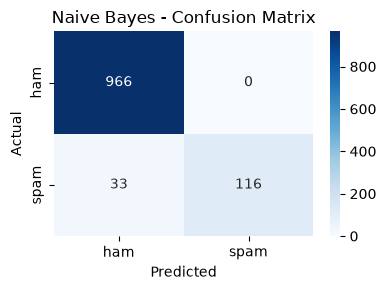

===== Logistic Regression =====
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       966
        spam       1.00      0.76      0.86       149

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.92      1115
weighted avg       0.97      0.97      0.97      1115



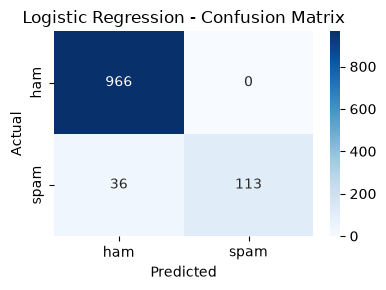

In [6]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

for name, model in [("Naive Bayes", nb), ("Logistic Regression", lr)]:
    pred = model.predict(Xte)
    print("=====", name, "=====")
    print(classification_report(y_test, pred, target_names=["ham", "spam"]))

    plt.figure(figsize=(4, 3))
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues",
                xticklabels=["ham", "spam"], yticklabels=["ham", "spam"])
    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.savefig(f"cm_{name.replace(' ', '_')}.png", dpi=300)
    plt.show()

In [7]:
import joblib

joblib.dump(vec, "vectorizer.pkl")
joblib.dump(nb, "model.pkl")

def predict(msg):
    pred = nb.predict(vec.transform([msg]))[0]
    return "SPAM" if pred == 1 else "NOT SPAM"

print(predict("Congratulations! You won a free prize, click now to claim"))
print(predict("Hey, are we meeting at 5 today?"))
print(predict("URGENT! Your account is suspended, call 09061234567 now"))

SPAM
NOT SPAM
NOT SPAM


In [8]:
def predict_proba(msg):
    p = nb.predict_proba(vec.transform([msg]))[0][1]
    label = "SPAM" if p >= 0.5 else "NOT SPAM"
    return f"{label} (spam probability: {p:.2f})"

tests = [
    "URGENT! Your account is suspended, call 09061234567 now",
    "WINNER!! As a valued network customer you have been selected to receive a 900 pound prize reward. Call 09061701461 to claim.",
    "Free entry in 2 a weekly comp to win FA Cup tickets. Text WIN to 87121 now!",
    "Hey, are we meeting at 5 today?",
    "Can you send me the notes from class?"
]
for t in tests:
    print(predict_proba(t), "<-", t[:50])

NOT SPAM (spam probability: 0.46) <- URGENT! Your account is suspended, call 0906123456
SPAM (spam probability: 0.98) <- WINNER!! As a valued network customer you have bee
SPAM (spam probability: 0.83) <- Free entry in 2 a weekly comp to win FA Cup ticket
NOT SPAM (spam probability: 0.00) <- Hey, are we meeting at 5 today?
NOT SPAM (spam probability: 0.04) <- Can you send me the notes from class?


In [9]:
def interactive_test():
    print("Type a message to check (or type 'quit' to stop)")
    while True:
        msg = input("Message: ")
        if msg.strip().lower() == "quit":
            print("Done.")
            break
        print("->", predict_proba(msg))

interactive_test()

Type a message to check (or type 'quit' to stop)
-> NOT SPAM (spam probability: 0.04)
-> NOT SPAM (spam probability: 0.13)
Done.
